In [ ]:
# FASE II - SISTEMA INTELIGENTE DE PRIORIZACION DE EVENTOS DE CIBERSEGURIDAD
# Configuración del entorno

# Librerias para manejo de datos, calculos y visualizaciones.
import sys
import platform
import random
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import joblib

# Herramientas para preparar datos, entrenar modelos y evaluar resultados.
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

# Se establece una semilla fija para facilitar la reproduccion de los experimentos.
SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)

# Configuración general de las graficas.
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["figure.dpi"] = 110

# Registro de versiones de las principales dependencias.
print("=" * 65)
print("Configuración del entorno")
print("=" * 65)
print(f"Python:         {sys.version.split()[0]}")
print(f"Sistema:        {platform.system()}")
print(f"NumPy:          {np.__version__}")
print(f"Pandas:         {pd.__version__}")
print(f"Matplotlib:     {matplotlib.__version__}")
print(f"Seaborn:        {sns.__version__}")
print(f"Scikit-learn:   {sklearn.__version__}")
print(f"Joblib:         {joblib.__version__}")
print(f"Semilla:        {SEMILLA}")
print("\nEstado: entorno configurado correctamente.")

Configuración del entorno
Python:         3.13.18
Sistema:        Linux
NumPy:          2.1.3
Pandas:         2.2.3
Matplotlib:     3.10.0
Seaborn:        0.13.2
Scikit-learn:   1.6.1
Joblib:         1.6.0
Semilla:        42

Estado: entorno configurado correctamente.


In [ ]:
# Carga inicial del dataset CSE-CIC-IDS2018

# Fuente publica oficial del conjunto de datos.
url = (
    "https://cse-cic-ids2018.s3.ca-central-1.amazonaws.com/"
    "Processed%20Traffic%20Data%20for%20ML%20Algorithms/"
    "Thursday-01-03-2018_TrafficForML_CICFlowMeter.csv"
)

# Se carga la muestra inicial para comprobar la lectura del archivo.
# En las siguientes celdas se seleccionarán datos de varios escenarios.
try:
    df = pd.read_csv(url, nrows=50000, low_memory=False)

    # Se eliminan los espacios adicionales en los nombres de las columnas.
    df.columns = df.columns.str.strip()

    print("=" * 65)
    print("Carga inicial del dataset CSE-CIC-IDS2018")
    print("=" * 65)
    print(f"Registros cargados: {len(df):,}")
    print(f"Columnas disponibles: {df.shape[1]}")
    print(f"Memoria utilizada: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

    # Se realiza la identificación de la columna con la clasificación original.
    if "Label" in df.columns:
        print("\nEtiquetas identificadas:")
        print(df["Label"].value_counts().to_string())
    else:
        print("\nAdvertencia: no se encontro la columna 'Label'.")

    # Se despliega una muestra inicial.
    print("\nPrimeros 5 registros (columnas seleccionadas):")
    columnas = [
        c for c in ["Dst Port", "Protocol", "Flow Duration", "Label"]
        if c in df.columns
    ]
    display(df[columnas].head())

    print("\nEstado: carga inicial completada correctamente.")

except Exception as error:
    print(f"Error durante la carga: {error}")
    print("Verificar la conexion a Internet y el acceso al archivo CSV.")

Carga inicial del dataset CSE-CIC-IDS2018
Registros cargados: 50,000
Columnas disponibles: 80
Memoria utilizada: 199.38 MB

Etiquetas identificadas:
Label
Benign    49996
Label         4

Primeros 5 registros (columnas seleccionadas):


,Dst Port,Protocol,Flow Duration,Label
0,0,0,115307855,Benign
1,0,0,60997457,Benign
2,67,17,61149019,Benign
3,0,0,60997555,Benign
4,0,0,61997503,Benign



Estado: carga inicial completada correctamente.


In [ ]:
# Exploración y selección de eventos

import requests
from urllib.parse import quote

print("=" * 65)
print("Exploración y selección de eventos")
print("=" * 65)

# Archivos publicos con diferentes escenarios de ciberseguridad.
archivos = [
    "Wednesday-14-02-2018_TrafficForML_CICFlowMeter.csv",
    "Thursday-15-02-2018_TrafficForML_CICFlowMeter.csv",
    "Friday-16-02-2018_TrafficForML_CICFlowMeter.csv"
]

base_url = (
    "https://cse-cic-ids2018.s3.ca-central-1.amazonaws.com/"
    "Processed%20Traffic%20Data%20for%20ML%20Algorithms/"
)

# Se realiza la configuración del muestreo reproducible.
MAX_POR_CLASE = 2000
TAMANO_BLOQUE = 50000
rng = np.random.default_rng(SEMILLA)

muestras = []
resumen = []

# Se realiza el procesamiento de los archivos sin descargarlos completos en memoria.
for archivo in archivos:
    seleccion = {}
    etiquetas_detectadas = set()
    total_leidos = 0

    try:
        url = base_url + quote(archivo)

        with requests.get(url, stream=True, timeout=180) as respuesta:
            respuesta.raise_for_status()
            respuesta.raw.decode_content = True

            for bloque in pd.read_csv(
                respuesta.raw,
                chunksize=TAMANO_BLOQUE,
                low_memory=False
            ):
                bloque.columns = bloque.columns.str.strip()
                bloque["Label"] = bloque["Label"].astype(str).str.strip()

                # Se eliminan los encabezados repetidos y registros duplicados.
                bloque = bloque[bloque["Label"] != "Label"]
                bloque = bloque.drop_duplicates()

                total_leidos += len(bloque)

                # Se realiza una seleccion aleatoria mediante muestreo de reservorio.
                # Cada registro único procesado puede sustituir uno anterior.
                for etiqueta, grupo in bloque.groupby("Label"):
                    etiquetas_detectadas.add(etiqueta)

                    if etiqueta not in seleccion:
                        seleccion[etiqueta] = {
                            "datos": [],
                            "vistos": 0,
                            "firmas": set()
                        }

                    estado = seleccion[etiqueta]

                    for fila in grupo.itertuples(index=False, name=None):
                        # Representación del registro para evitar duplicados.
                        firma = tuple(str(valor) for valor in fila)

                        if firma in estado["firmas"]:
                            continue

                        estado["firmas"].add(firma)
                        estado["vistos"] += 1

                        if len(estado["datos"]) < MAX_POR_CLASE:
                            estado["datos"].append(fila)
                        else:
                            posicion = rng.integers(0, estado["vistos"])
                            if posicion < MAX_POR_CLASE:
                                estado["datos"][posicion] = fila

        # Se realiza la consolidación de los registros seleccionados de cada archivo.
        for etiqueta, estado in seleccion.items():
            if estado["datos"]:
                parte = pd.DataFrame(
                    estado["datos"],
                    columns=bloque.columns
                )
                muestras.append(parte)

        resumen.append({
            "Archivo": archivo.split("_")[0],
            "Estado": "Correcto",
            "Etiquetas": len(etiquetas_detectadas),
            "Registros seleccionados": sum(
                len(e["datos"]) for e in seleccion.values()
            )
        })

    except Exception as error:
        resumen.append({
            "Archivo": archivo.split("_")[0],
            "Estado": str(error)[:70],
            "Etiquetas": len(etiquetas_detectadas),
            "Registros seleccionados": 0
        })

# Se realiza la consolidación de los datos para continuar con la limpieza.
if muestras:
    df = pd.concat(muestras, ignore_index=True)
    df.columns = df.columns.str.strip()

    print("\nResumen de archivos consultados:")
    display(pd.DataFrame(resumen))

    print("\nDistribución de etiquetas seleccionadas:")
    display(df["Label"].value_counts().to_frame("Registros"))

    print(f"\nTotal de registros seleccionados: {len(df):,}")
    print(f"Columnas disponibles: {df.shape[1]}")
    print("\nEstado: selección aleatoria completada.")
else:
    print("\nNo se pudieron seleccionar registros.")
    display(pd.DataFrame(resumen))


Exploración y selección de eventos

Resumen de archivos consultados:


,Archivo,Estado,Etiquetas,Registros seleccionados
0,Wednesday-14-02-2018,Correcto,3,6000
1,Thursday-15-02-2018,Correcto,3,6000
2,Friday-16-02-2018,Correcto,3,6000



Distribución de etiquetas seleccionadas:


,Registros
Label,
Benign,6000
FTP-BruteForce,2000
SSH-Bruteforce,2000
DoS attacks-GoldenEye,2000
DoS attacks-Slowloris,2000
DoS attacks-SlowHTTPTest,2000
DoS attacks-Hulk,2000



Total de registros seleccionados: 18,000
Columnas disponibles: 80

Estado: selección aleatoria completada.


Limpieza, preparación y visualización de datos
Registros iniciales: 18,000
Encabezados repetidos eliminados: 0
Valores faltantes detectados: 18,010
Valores infinitos detectados: 28
Registros duplicados eliminados: 4,477
Columnas completamente vacias: 1
Filas incompletas eliminadas: 0

Registros finales: 13,523
Columnas finales: 79
Valores faltantes restantes: 38

Comparación de eventos antes y después de la limpieza:


,Antes,Despues,Eliminados,Reduccion (%)
Label,,,,
Benign,6000,5898,102,1.70
DoS attacks-GoldenEye,2000,2000,0,0.00
DoS attacks-Hulk,2000,1937,63,3.15
DoS attacks-SlowHTTPTest,2000,42,1958,97.90
DoS attacks-Slowloris,2000,1952,48,2.40
FTP-BruteForce,2000,42,1958,97.90
SSH-Bruteforce,2000,1652,348,17.40


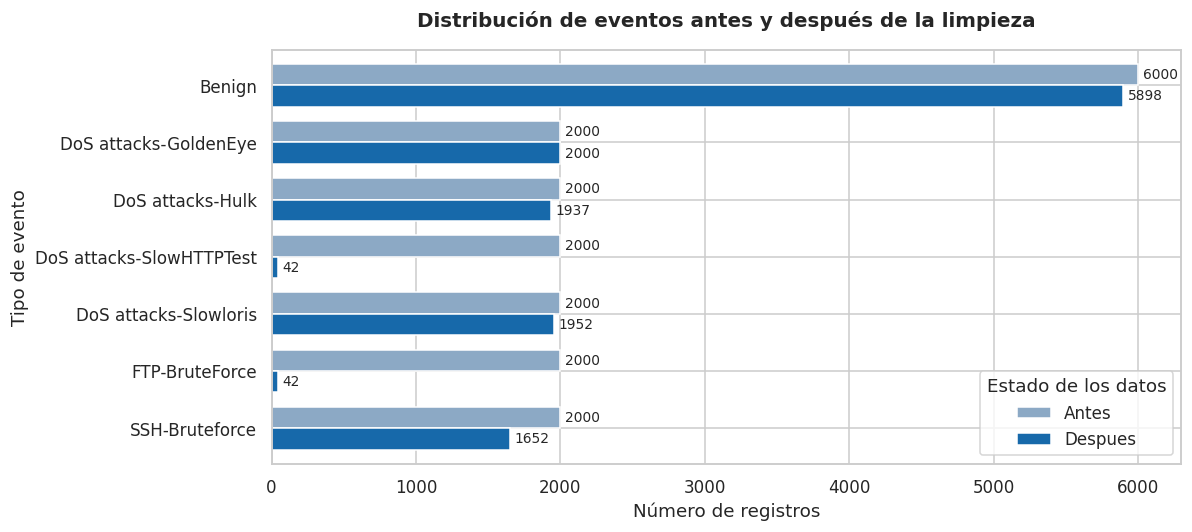


Estado: limpieza y visualización completadas.


In [ ]:
# Limpieza, preparación y visualización de datos

print("=" * 65)
print("Limpieza, preparación y visualización de datos")
print("=" * 65)

# Se conserva una copia de los datos para comparar antes y despues.
df_original = df.copy()
registros_iniciales = len(df_original)
distribucion_antes = df_original["Label"].astype(str).str.strip().value_counts()

# Se eliminan los encabezados repetidos y se normalizan las etiquetas.
df["Label"] = df["Label"].astype(str).str.strip()
encabezados = int(df["Label"].eq("Label").sum())
df = df[df["Label"] != "Label"].copy()

# Se convierten las caracteristicas a valores numericos.
# Los valores no convertibles se identifican como NaN.
columnas_numericas = df.columns.drop("Label")
df[columnas_numericas] = df[columnas_numericas].apply(
    pd.to_numeric, errors="coerce"
)

# Se realiza la identificación de valores faltantes e infinitos.
faltantes_iniciales = int(df.isna().sum().sum())
infinitos = int(np.isinf(df[columnas_numericas].to_numpy(dtype=float)).sum())

# Se realiza la sustitución de infinitos por NaN para evitar errores posteriores.
df.replace([np.inf, -np.inf], np.nan, inplace=True)

# Se eliminan los duplicados exactos, conservando un solo registro.
duplicados = int(df.duplicated().sum())
df.drop_duplicates(inplace=True)

# Se eliminan las columnas completamente vacias.
columnas_vacias = df.columns[df.isna().all()].tolist()
df.drop(columns=columnas_vacias, inplace=True)

# Se eliminan las filas con menos del 80% de caracteristicas disponibles.
caracteristicas = df.columns.drop("Label")
minimo_validas = int(np.ceil(len(caracteristicas) * 0.80))
filas_incompletas = int(
    (df[caracteristicas].notna().sum(axis=1) < minimo_validas).sum()
)
df = df[
    df[caracteristicas].notna().sum(axis=1) >= minimo_validas
].copy()

df.reset_index(drop=True, inplace=True)

# Se imprime el resumen de calidad de los datos.
print(f"Registros iniciales: {registros_iniciales:,}")
print(f"Encabezados repetidos eliminados: {encabezados:,}")
print(f"Valores faltantes detectados: {faltantes_iniciales:,}")
print(f"Valores infinitos detectados: {infinitos:,}")
print(f"Registros duplicados eliminados: {duplicados:,}")
print(f"Columnas completamente vacias: {len(columnas_vacias):,}")
print(f"Filas incompletas eliminadas: {filas_incompletas:,}")
print(f"\nRegistros finales: {len(df):,}")
print(f"Columnas finales: {df.shape[1]}")
print(f"Valores faltantes restantes: {int(df.isna().sum().sum()):,}")

# Se realiza la comparación de los registros de cada categoria antes y despues.
comparacion = pd.DataFrame({
    "Antes": distribucion_antes,
    "Despues": df["Label"].value_counts()
}).fillna(0).astype(int)

comparacion["Eliminados"] = comparacion["Antes"] - comparacion["Despues"]
comparacion["Reduccion (%)"] = (
    comparacion["Eliminados"] / comparacion["Antes"] * 100
).round(2)

print("\nComparación de eventos antes y después de la limpieza:")
display(comparacion)

# Se genera la gráfica de barras horizontales para identificar cambios por categoria.
ax = comparacion[["Antes", "Despues"]].plot(
    kind="barh",
    figsize=(11, 5),
    width=0.75,
    color=["#8CA9C5", "#1769AA"]
)

ax.set_title("Distribución de eventos antes y después de la limpieza",
             fontsize=13, fontweight="bold", pad=15)
ax.set_xlabel("Número de registros")
ax.set_ylabel("Tipo de evento")
ax.legend(title="Estado de los datos")
ax.invert_yaxis()

# Agregamos los valores a las barras para facilitar su lectura.
for contenedor in ax.containers:
    ax.bar_label(contenedor, padding=3, fontsize=9)

plt.tight_layout()
plt.savefig("celda4_comparacion_limpieza.png", dpi=150, bbox_inches="tight")
print("\n")
plt.show()

print("\nEstado: limpieza y visualización completadas.")

Contexto sintético y asignación de prioridades
Registros procesados: 13,523
Variables totales: 84

Distribución de prioridades:


,Registros
Prioridad,
Media,6589
Baja,3070
Alta,2720
Crítica,1144



Prioridades por tipo de evento:


Prioridad,Baja,Media,Alta,Crítica
Label,,,,
Benign,3070,2739,89,0
DoS attacks-GoldenEye,0,1004,694,302
DoS attacks-Hulk,0,1001,665,271
DoS attacks-SlowHTTPTest,0,19,17,6
DoS attacks-Slowloris,0,969,702,281
FTP-BruteForce,0,20,15,7
SSH-Bruteforce,0,837,538,277



Ejemplos de eventos priorizados:


,Label,Criticidad_Activo,Exposicion_Internet,Cuenta_Privilegiada,Puntaje_Riesgo,Prioridad
0,Benign,Alta,0,0,2,Media
1,Benign,Media,0,0,1,Baja
2,Benign,Alta,0,1,3,Media
3,Benign,Media,1,0,2,Media
4,Benign,Baja,0,0,0,Baja
5,Benign,Alta,1,0,3,Media
6,Benign,Alta,0,0,2,Media
7,Benign,Alta,1,0,3,Media
8,Benign,Baja,0,0,0,Baja
9,Benign,Media,0,0,1,Baja


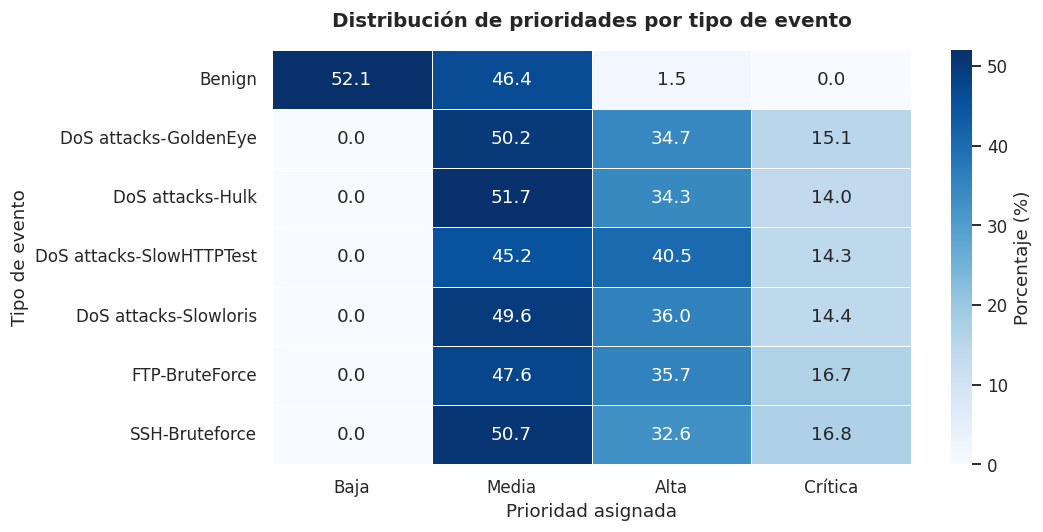


Estado: prioridades asignadas correctamente.


In [ ]:
# Contexto sintético y asignación de prioridades

print("=" * 65)
print("Contexto sintético y asignación de prioridades")
print("=" * 65)

# Generación de condiciones de seguridad simuladas y reproducibles.
rng = np.random.default_rng(SEMILLA)
n = len(df)

# Definición de la criticidad del activo: importancia del sistema afectado.
df["Criticidad_Activo"] = rng.choice(
    ["Baja", "Media", "Alta"],
    size=n,
    p=[0.30, 0.45, 0.25]
)

# Definición de indicadores sintéticos del contexto del evento.
df["Exposicion_Internet"] = rng.choice(
    [0, 1], size=n, p=[0.60, 0.40]
)
df["Cuenta_Privilegiada"] = rng.choice(
    [0, 1], size=n, p=[0.85, 0.15]
)

# Definición de la puntuación inicial según la categoría del evento.
# No una clasificación oficial.
riesgo_evento = {
    "Benign": 0,
    "FTP-BruteForce": 2,
    "SSH-Bruteforce": 2,
    "DoS attacks-GoldenEye": 2,
    "DoS attacks-Hulk": 2,
    "DoS attacks-SlowHTTPTest": 2,
    "DoS attacks-Slowloris": 2
}

# Cálculo del riesgo combinando evento y contexto.
puntos_activo = {"Baja": 0, "Media": 1, "Alta": 2}

df["Puntaje_Riesgo"] = (
    df["Label"].map(riesgo_evento)
    + df["Criticidad_Activo"].map(puntos_activo)
    + df["Exposicion_Internet"]
    + df["Cuenta_Privilegiada"]
)

# Transformación de la puntuación en cuatro prioridades.
condiciones = [
    df["Puntaje_Riesgo"] <= 1,
    df["Puntaje_Riesgo"].between(2, 3),
    df["Puntaje_Riesgo"] == 4,
    df["Puntaje_Riesgo"] >= 5
]

df["Prioridad"] = np.select(
    condiciones,
    ["Baja", "Media", "Alta", "Crítica"],
    default="Sin clasificar"
)

# Verificación de que todos los eventos tengan una prioridad.
assert df["Prioridad"].ne("Sin clasificar").all()
assert df["Puntaje_Riesgo"].notna().all()

print(f"Registros procesados: {len(df):,}")
print(f"Variables totales: {df.shape[1]}")
print("\nDistribución de prioridades:")
display(df["Prioridad"].value_counts().to_frame("Registros"))

# Se realiza la comprobación de la relación entre categorías originales y prioridades.
print("\nPrioridades por tipo de evento:")
tabla_prioridades = pd.crosstab(df["Label"], df["Prioridad"])
display(tabla_prioridades.reindex(
    columns=["Baja", "Media", "Alta", "Crítica"],
    fill_value=0
))

# Se muestran ejemplos para verificar la lógica aplicada.
print("\nEjemplos de eventos priorizados:")
display(df[[
    "Label", "Criticidad_Activo", "Exposicion_Internet",
    "Cuenta_Privilegiada", "Puntaje_Riesgo", "Prioridad"
]].head(10))

# Visualización de la distribución porcentual de prioridades por evento.
# Los porcentajes permiten comparar categorías de distintos tamaños.
tabla_porcentajes = pd.crosstab(
    df["Label"], df["Prioridad"], normalize="index"
) * 100

tabla_porcentajes = tabla_porcentajes.reindex(
    columns=["Baja", "Media", "Alta", "Crítica"], fill_value=0
)

plt.figure(figsize=(10, 5))
sns.heatmap(
    tabla_porcentajes,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    linewidths=0.5,
    cbar_kws={"label": "Porcentaje (%)"}
)

plt.title("Distribución de prioridades por tipo de evento",
          fontsize=13, fontweight="bold", pad=15)
plt.xlabel("Prioridad asignada")
plt.ylabel("Tipo de evento")
plt.tight_layout()
plt.savefig("celda5_prioridades_por_evento.png",
            dpi=150, bbox_inches="tight")
print("\n")
plt.show()

print("\nEstado: prioridades asignadas correctamente.")

Análisis y visualización de prioridades
Total de eventos analizados: 13,523

Distribución general de prioridades:


,Registros,Porcentaje (%)
Prioridad,,
Baja,3070,22.70
Media,6589,48.72
Alta,2720,20.11
Crítica,1144,8.46



Relación entre clase mayoritaria y minoritaria: 5.76:1




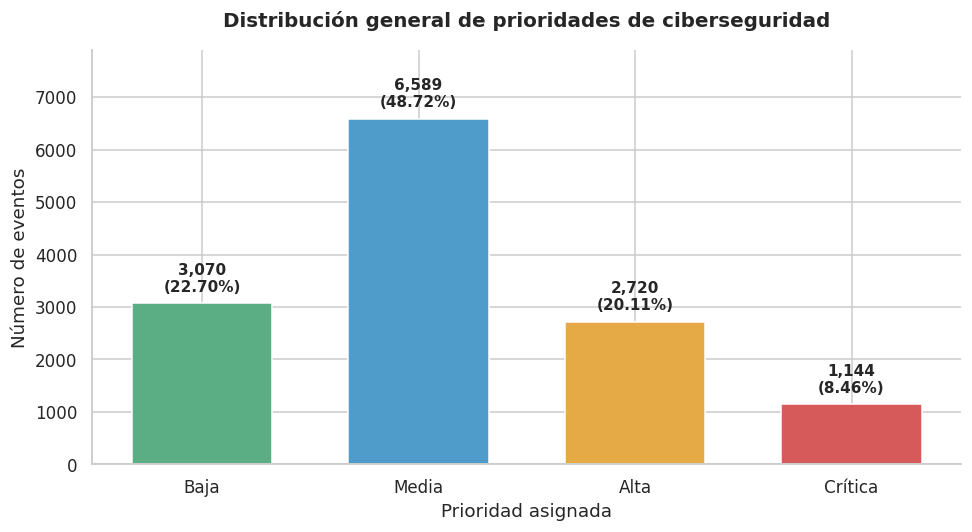


Estado: cuatro prioridades representadas correctamente.


In [ ]:
# Análisis y visualización de prioridades

print("=" * 65)
print("Análisis y visualización de prioridades")
print("=" * 65)

# Se define el orden operativo de las cuatro prioridades.
orden_prioridades = ["Baja", "Media", "Alta", "Crítica"]

# Se realiza el cálculo de la cantidad y el porcentaje de registros por prioridad.
conteos = df["Prioridad"].value_counts().reindex(
    orden_prioridades, fill_value=0
)
porcentajes = (conteos / len(df) * 100).round(2)

# Se construye una tabla para facilitar la interpretación.
resumen_prioridades = pd.DataFrame({
    "Registros": conteos,
    "Porcentaje (%)": porcentajes
})

print(f"Total de eventos analizados: {len(df):,}")
print("\nDistribución general de prioridades:")
display(resumen_prioridades)

# Se realiza el cálculo de la relación entre la clase más frecuente y la menos frecuente.
clases_presentes = conteos[conteos > 0]
relacion = clases_presentes.max() / clases_presentes.min()

print(f"\nRelación entre clase mayoritaria y minoritaria: {relacion:.2f}:1")

# Se genera una gráfica de barras con cantidades y porcentajes.
colores = ["#5BAE83", "#4F9CCB", "#E5AA45", "#D65A59"]

fig, ax = plt.subplots(figsize=(9, 5))
barras = ax.bar(
    orden_prioridades,
    conteos.values,
    color=colores,
    width=0.65
)

ax.set_title(
    "Distribución general de prioridades de ciberseguridad",
    fontsize=13, fontweight="bold", pad=15
)
ax.set_xlabel("Prioridad asignada")
ax.set_ylabel("Número de eventos")
ax.set_ylim(0, conteos.max() * 1.20)

# Se muestra cantidad y porcentaje sobre cada barra.
for barra, cantidad, porcentaje in zip(
    barras, conteos.values, porcentajes.values
):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + conteos.max() * 0.025,
        f"{cantidad:,}\n({porcentaje:.2f}%)",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()

# Se guarda la gráfica como evidencia para el reporte técnico.
plt.savefig(
    "celda6_distribucion_prioridades.png",
    dpi=150,
    bbox_inches="tight"
)
print("\n")
plt.show()

# Se verifica que las cuatro prioridades estén representadas.
if (conteos > 0).all():
    print("\nEstado: cuatro prioridades representadas correctamente.")
else:
    print("\nAdvertencia: existe alguna prioridad sin registros.")

In [ ]:
# Preparación de datos para entrenamiento y prueba

from sklearn.impute import SimpleImputer

print("=" * 65)
print("Preparación de datos para entrenamiento y prueba")
print("=" * 65)

# Se seleccionan las variables utilizadas en la política académica.
# Se realiza la exclusión Puntaje_Riesgo para evitar revelar directamente el resultado.
variables = [
    "Label",
    "Criticidad_Activo",
    "Exposicion_Internet",
    "Cuenta_Privilegiada"
]

X = df[variables].copy()
y = df["Prioridad"].copy()

# Se realiza la identificación de las variables categóricas y numéricas.
categoricas = ["Label", "Criticidad_Activo"]
numericas = ["Exposicion_Internet", "Cuenta_Privilegiada"]

# Se dividen los registros conservando la proporción de prioridades.
# Primero se reserva el 15% para la prueba final.
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.15, random_state=SEMILLA, stratify=y
)

# Del 85% restante se reserva la proporción necesaria para validación.
# El resultado aproximado es 70% entrenamiento, 15% validación y 15% prueba.
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.15 / 0.85,
    random_state=SEMILLA,
    stratify=y_temp
)

# Se preparan las transformaciones que se ajustarán solo con entrenamiento.
# Las variables categóricas se codifican y las numéricas se imputan.
preprocesador = ColumnTransformer(
    transformers=[
        ("categoricas", Pipeline([
            ("imputador", SimpleImputer(strategy="most_frequent")),
            ("codificador", OneHotEncoder(handle_unknown="ignore"))
        ]), categoricas),
        ("numericas", Pipeline([
            ("imputador", SimpleImputer(strategy="median")),
            ("escalador", StandardScaler())
        ]), numericas)
    ]
)

# Se muestra un resumen de los conjuntos generados.
resumen = pd.DataFrame({
    "Conjunto": ["Entrenamiento", "Validación", "Prueba"],
    "Registros": [len(X_train), len(X_val), len(X_test)]
})
resumen["Porcentaje (%)"] = (
    resumen["Registros"] / len(df) * 100
).round(2)

print(f"Total de registros: {len(df):,}")
print(f"Variables predictoras: {len(variables)}")
print("\nDistribución de conjuntos:")
display(resumen)

# Se realiza la verificación de las cuatro prioridades en cada partición.
distribucion = pd.DataFrame({
    "Entrenamiento": y_train.value_counts(),
    "Validación": y_val.value_counts(),
    "Prueba": y_test.value_counts()
}).reindex(["Baja", "Media", "Alta", "Crítica"])

print("\nDistribución de prioridades por conjunto:")
display(distribucion)

# Se realiza la comprobación de que no existan índices compartidos entre conjuntos.
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)

print("\nEstado: datos preparados correctamente para entrenamiento.")

Preparación de datos para entrenamiento y prueba
Total de registros: 13,523
Variables predictoras: 4

Distribución de conjuntos:


,Conjunto,Registros,Porcentaje (%)
0,Entrenamiento,9465,69.99
1,Validación,2029,15.00
2,Prueba,2029,15.00



Distribución de prioridades por conjunto:


,Entrenamiento,Validación,Prueba
Prioridad,,,
Baja,2149,460,461
Media,4612,989,988
Alta,1904,408,408
Crítica,800,172,172



Estado: datos preparados correctamente para entrenamiento.


In [ ]:
# Entrenamiento y comparación inicial de modelos

import time

print("=" * 65)
print("Entrenamiento y comparación inicial de modelos")
print("=" * 65)

# Se realiza la definición de tres algoritmos con una configuracion reproducible.
modelos = {
    "Regresión logística": LogisticRegression(
        max_iter=1000, random_state=SEMILLA
    ),
    "Árbol de decisión": DecisionTreeClassifier(
        max_depth=8, random_state=SEMILLA
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, max_depth=10,
        random_state=SEMILLA, n_jobs=-1
    )
}

resultados = []
modelos_entrenados = {}

# Se realiza el entrenamiento de cada modelo con el mismo conjunto de datos.
# El Pipeline aplica el preprocesamiento solo a los datos de entrenamiento.
for nombre, algoritmo in modelos.items():
    pipeline = Pipeline([
        ("preprocesamiento", preprocesador),
        ("modelo", algoritmo)
    ])

    inicio = time.perf_counter()
    pipeline.fit(X_train, y_train)
    tiempo = time.perf_counter() - inicio

    # Se evalúa exclusivamente con el conjunto de validacion.
    predicciones = pipeline.predict(X_val)

    resultados.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_val, predicciones),
        "Precision": precision_score(
            y_val, predicciones, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_val, predicciones, average="macro", zero_division=0
        ),
        "F1-score": f1_score(
            y_val, predicciones, average="macro", zero_division=0
        ),
        "Entrenamiento (s)": tiempo
    })

    modelos_entrenados[nombre] = pipeline

# Se ordenan los modelos de acuerdo con su F1-score.
comparacion_modelos = pd.DataFrame(resultados).sort_values(
    "F1-score", ascending=False
).reset_index(drop=True)

print("\nResultados sobre el conjunto de validación:")
display(comparacion_modelos.round(4))

# Se selecciona preliminarmente el modelo con mejor F1-score.
nombre_mejor_modelo = comparacion_modelos.loc[0, "Modelo"]
mejor_modelo = modelos_entrenados[nombre_mejor_modelo]

print(f"\nModelo mejor evaluado: {nombre_mejor_modelo}")
print(f"F1-score macro: {comparacion_modelos.loc[0, 'F1-score']:.4f}")

# Se verifica especificamente la identificacion de eventos criticos.
print("\nRecall de la prioridad Crítica por modelo:")
for nombre, pipeline in modelos_entrenados.items():
    pred = pipeline.predict(X_val)
    recall_critico = recall_score(
        y_val.eq("Crítica"),
        pd.Series(pred, index=y_val.index).eq("Crítica"),
        zero_division=0
    )
    print(f"{nombre}: {recall_critico:.4f}")

print("\nEstado: entrenamiento y comparación completados.")

Entrenamiento y comparación inicial de modelos

Resultados sobre el conjunto de validación:


,Modelo,Accuracy,Precision,Recall,F1-score,Entrenamiento (s)
0,Regresión logística,1.0,1.0,1.0,1.0,0.2418
1,Árbol de decisión,1.0,1.0,1.0,1.0,0.0561
2,Random Forest,1.0,1.0,1.0,1.0,0.3961



Modelo mejor evaluado: Regresión logística
F1-score macro: 1.0000

Recall de la prioridad Crítica por modelo:
Regresión logística: 1.0000
Árbol de decisión: 1.0000
Random Forest: 1.0000

Estado: entrenamiento y comparación completados.


Comparación y análisis de desempeño

Métricas de los modelos sobre validación:


,Accuracy,Precision,Recall,F1-score
Modelo,,,,
Regresión logística,1.0,1.0,1.0,1.0
Árbol de decisión,1.0,1.0,1.0,1.0
Random Forest,1.0,1.0,1.0,1.0


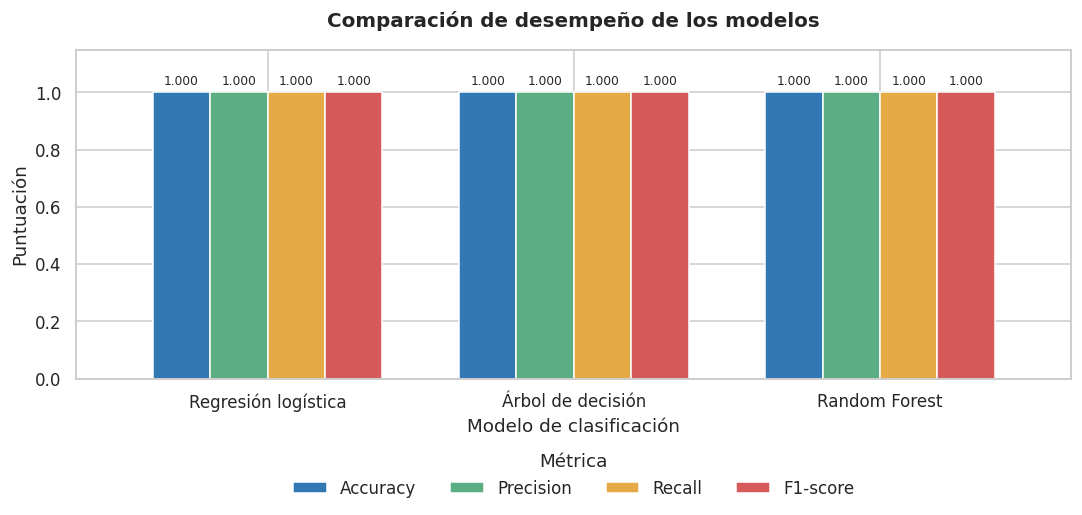


Comparación con la política académica de referencia:


,Modelo,Accuracy,Precision,Recall,F1-score
0,Regresión logística,1.0,1.0,1.0,1.0
1,Árbol de decisión,1.0,1.0,1.0,1.0
2,Random Forest,1.0,1.0,1.0,1.0
3,Política de reglas,1.0,1.0,1.0,1.0



Resultados por prioridad del modelo seleccionado:
              precision    recall  f1-score   support

        Baja       1.00      1.00      1.00       460
       Media       1.00      1.00      1.00       989
        Alta       1.00      1.00      1.00       408
     Crítica       1.00      1.00      1.00       172

    accuracy                           1.00      2029
   macro avg       1.00      1.00      1.00      2029
weighted avg       1.00      1.00      1.00      2029


Estado: comparación y análisis completados.


In [ ]:
# Comparación y análisis de desempeño

print("=" * 65)
print("Comparación y análisis de desempeño")
print("=" * 65)

# Se organizan las métricas obtenidas en la celda anterior.
metricas = ["Accuracy", "Precision", "Recall", "F1-score"]
tabla_metricas = comparacion_modelos.set_index("Modelo")[metricas]

print("\nMétricas de los modelos sobre validación:")
display(tabla_metricas.round(4))

# Se realiza la comparación visual de las cuatro métricas de clasificación.
ax = tabla_metricas.plot(
    kind="bar",
    figsize=(10, 5),
    width=0.75,
    color=["#3178B5", "#5BAE83", "#E5AA45", "#D65A59"]
)

ax.set_title(
    "Comparación de desempeño de los modelos",
    fontsize=13, fontweight="bold", pad=15
)
ax.set_xlabel("Modelo de clasificación")
ax.set_ylabel("Puntuación")
ax.set_ylim(0, 1.15)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)

# Se coloca la leyenda debajo de la gráfica para evitar superposiciones.
ax.legend(
    title="Métrica",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.18),
    ncol=4,
    frameon=False
)

# Se muestran los valores de las métricas sobre cada barra.
for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%.3f", padding=3, fontsize=8)

# Se ajustan los márgenes y se guarda la gráfica para el reporte técnico.
plt.tight_layout()
plt.savefig(
    "celda9_comparacion_modelos.png",
    dpi=150,
    bbox_inches="tight"
)
print("\n")
plt.show()

# Se realiza el cálculo de la prioridad directamente con la política original.
# Esta referencia permite verificar si el modelo mejora las reglas.
puntos_evento = X_val["Label"].map(riesgo_evento)
puntos_contexto = X_val["Criticidad_Activo"].map(puntos_activo)

puntaje_referencia = (
    puntos_evento
    + puntos_contexto
    + X_val["Exposicion_Internet"]
    + X_val["Cuenta_Privilegiada"]
)

# Se transforma la puntuación obtenida en los cuatro niveles de prioridad.
prioridad_referencia = np.select(
    [
        puntaje_referencia <= 1,
        puntaje_referencia.between(2, 3),
        puntaje_referencia == 4,
        puntaje_referencia >= 5
    ],
    ["Baja", "Media", "Alta", "Crítica"],
    default="Sin clasificar"
)

# Se evalúa la política de referencia utilizando las mismas métricas.
print("\nComparación con la política académica de referencia:")
referencia = pd.DataFrame([{
    "Modelo": "Política de reglas",
    "Accuracy": accuracy_score(y_val, prioridad_referencia),
    "Precision": precision_score(
        y_val, prioridad_referencia, average="macro", zero_division=0
    ),
    "Recall": recall_score(
        y_val, prioridad_referencia, average="macro", zero_division=0
    ),
    "F1-score": f1_score(
        y_val, prioridad_referencia, average="macro", zero_division=0
    )
}])

# Se integran los resultados de los modelos y la política de referencia.
comparacion_referencia = pd.concat([
    comparacion_modelos[["Modelo"] + metricas],
    referencia
], ignore_index=True)

display(comparacion_referencia.round(4))

# Se verifica el comportamiento del modelo seleccionado por prioridad.
pred_val = mejor_modelo.predict(X_val)

print("\nResultados por prioridad del modelo seleccionado:")
print(classification_report(
    y_val, pred_val,
    labels=["Baja", "Media", "Alta", "Crítica"],
    zero_division=0
))

print("\nEstado: comparación y análisis completados.")

Validación final y pruebas del modelo
Modelo evaluado: Regresión logística
Registros de prueba: 2,029

Resultados finales de clasificación:
              precision    recall  f1-score   support

        Baja     1.0000    1.0000    1.0000       461
       Media     1.0000    1.0000    1.0000       988
        Alta     1.0000    1.0000    1.0000       408
     Crítica     1.0000    1.0000    1.0000       172

    accuracy                         1.0000      2029
   macro avg     1.0000    1.0000    1.0000      2029
weighted avg     1.0000    1.0000    1.0000      2029





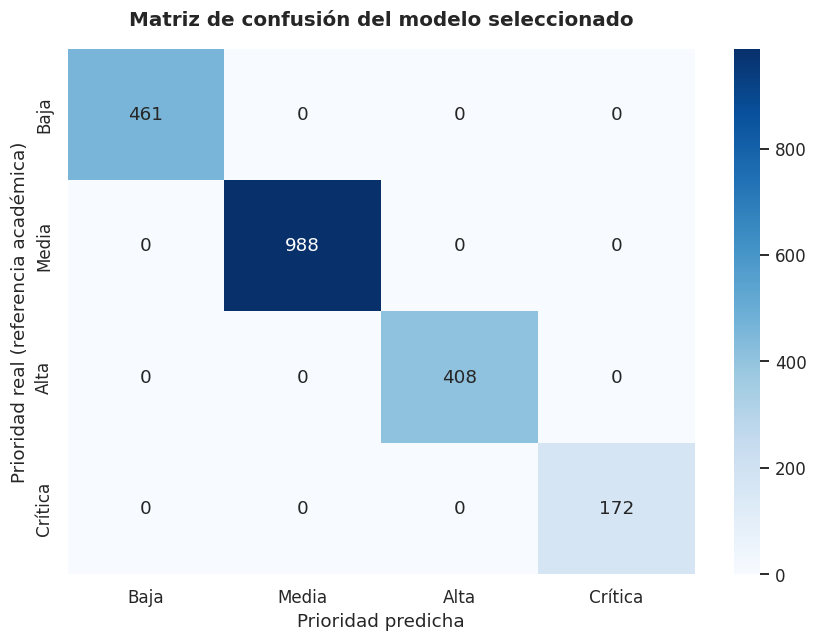


Evaluación de eventos críticos:
Eventos críticos de referencia: 172
Eventos críticos clasificados incorrectamente: 0

Resultados de los casos extremos:


,Label,Criticidad_Activo,Exposicion_Internet,Cuenta_Privilegiada,Prioridad_esperada,Prioridad_predicha,Coincide
0,Benign,Baja,0,0,Baja,Baja,True
1,Benign,Alta,1,1,Alta,Alta,True
2,SSH-Bruteforce,Alta,1,1,Crítica,Crítica,True
3,FTP-BruteForce,Baja,0,0,Media,Media,True
4,DoS attacks-Hulk,Alta,1,1,Crítica,Crítica,True
5,DoS attacks-SlowHTTPTest,Media,0,1,Alta,Alta,True



Casos coincidentes: 6 de 6

Estado: validación final y pruebas completadas.


In [ ]:
# Validación final y pruebas del modelo

print("=" * 65)
print("Validación final y pruebas del modelo")
print("=" * 65)

# Se evalúa el modelo seleccionado con los datos de prueba reservados.
pred_test = mejor_modelo.predict(X_test)
orden = ["Baja", "Media", "Alta", "Crítica"]

print(f"Modelo evaluado: {nombre_mejor_modelo}")
print(f"Registros de prueba: {len(X_test):,}")

# Se calculan las métricas generales y por prioridad.
print("\nResultados finales de clasificación:")
print(classification_report(
    y_test, pred_test, labels=orden, digits=4, zero_division=0
))

# Se construye la matriz de confusión para identificar errores.
matriz = confusion_matrix(y_test, pred_test, labels=orden)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    matriz, annot=True, fmt="d", cmap="Blues",
    xticklabels=orden, yticklabels=orden, ax=ax
)
ax.set_title("Matriz de confusión del modelo seleccionado",
             fontsize=13, fontweight="bold", pad=15)
ax.set_xlabel("Prioridad predicha")
ax.set_ylabel("Prioridad real (referencia académica)")
plt.tight_layout()
plt.savefig("celda10_matriz_confusion.png", dpi=150,
            bbox_inches="tight")
print("\n")
plt.show()

# Se identifican eventos críticos clasificados con menor prioridad.
criticos_reales = y_test.eq("Crítica").to_numpy()
criticos_omitidos = int(
    (criticos_reales & (pred_test != "Crítica")).sum()
)
total_criticos = int(criticos_reales.sum())

print("\nEvaluación de eventos críticos:")
print(f"Eventos críticos de referencia: {total_criticos}")
print(f"Eventos críticos clasificados incorrectamente: {criticos_omitidos}")

# Se preparan escenarios sintéticos para evaluar casos extremos.
# Estas entradas no forman parte del conjunto de prueba original.
casos_extremos = pd.DataFrame([
    ["Benign", "Baja", 0, 0],
    ["Benign", "Alta", 1, 1],
    ["SSH-Bruteforce", "Alta", 1, 1],
    ["FTP-BruteForce", "Baja", 0, 0],
    ["DoS attacks-Hulk", "Alta", 1, 1],
    ["DoS attacks-SlowHTTPTest", "Media", 0, 1]
], columns=variables)

# Se calculan las prioridades esperadas con la política de referencia.
puntajes = (
    casos_extremos["Label"].map(riesgo_evento)
    + casos_extremos["Criticidad_Activo"].map(puntos_activo)
    + casos_extremos["Exposicion_Internet"]
    + casos_extremos["Cuenta_Privilegiada"]
)

# Se asigna la prioridad esperada según la política académica.
# El valor predeterminado es texto para mantener compatibilidad con NumPy.
esperadas = np.select(
    [
        puntajes <= 1,
        puntajes.between(2, 3),
        puntajes == 4,
        puntajes >= 5
    ],
    ["Baja", "Media", "Alta", "Crítica"],
    default="Sin clasificar"
)

# Se comparan las predicciones del modelo con las reglas originales.
casos_extremos["Prioridad_esperada"] = esperadas
casos_extremos["Prioridad_predicha"] = mejor_modelo.predict(
    casos_extremos[variables]
)
casos_extremos["Coincide"] = (
    casos_extremos["Prioridad_esperada"]
    == casos_extremos["Prioridad_predicha"]
)

print("\nResultados de los casos extremos:")
display(casos_extremos)

print(f"\nCasos coincidentes: {casos_extremos['Coincide'].sum()} "
      f"de {len(casos_extremos)}")

print("\nEstado: validación final y pruebas completadas.")

Medición y comparación de tiempos de inferencia
Registros evaluados por repetición: 2,029
Repeticiones por modelo: 30

Comparación de tiempos de inferencia:


,Modelo,Promedio lote (ms),Desviación (ms),Promedio evento (ms)
0,Árbol de decisión,15.1543,5.5845,0.0075
1,Regresión logística,15.5835,5.5171,0.0077
2,Random Forest,73.0507,13.8719,0.0360


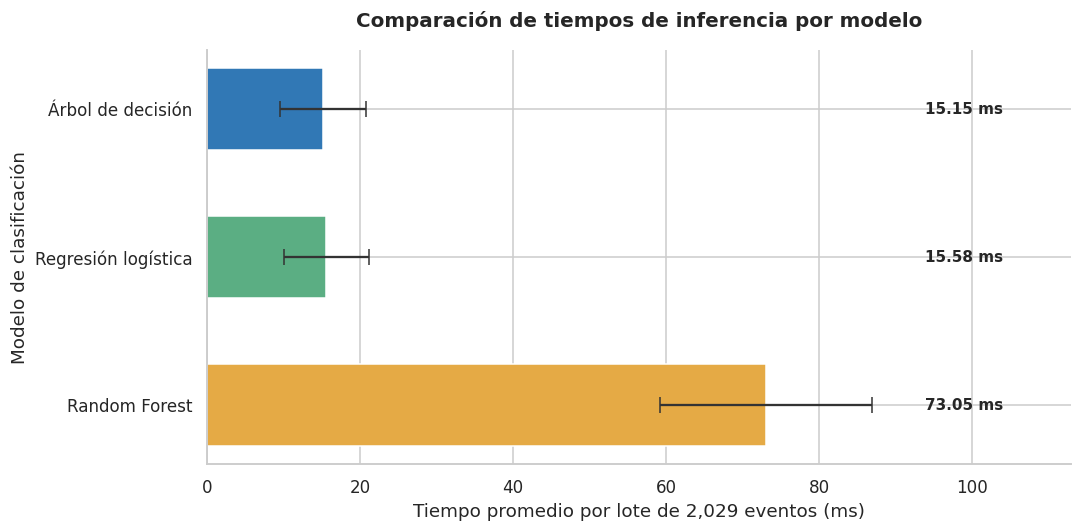


Modelo más rápido: Árbol de decisión
Tiempo promedio por lote: 15.15 ms

Estado: medición de tiempos completada.


In [ ]:
# Medición y comparación de tiempos de inferencia

import time

print("=" * 65)
print("Medición y comparación de tiempos de inferencia")
print("=" * 65)

# Se define el número de repeticiones para obtener mediciones estables.
REPETICIONES = 30
resultados_tiempos = []

# Se evalúan los tres modelos con los mismos registros de prueba.
for nombre, modelo in modelos_entrenados.items():

    # Se realiza una ejecución inicial para reducir el efecto de carga.
    modelo.predict(X_test)

    tiempos = []

    # Se mide el tiempo de predicción de todos los registros.
    for _ in range(REPETICIONES):
        inicio = time.perf_counter()
        modelo.predict(X_test)
        tiempos.append(time.perf_counter() - inicio)

    # Se calculan el promedio, la desviación y el tiempo por evento.
    promedio_ms = np.mean(tiempos) * 1000
    desviacion_ms = np.std(tiempos) * 1000
    tiempo_evento_ms = promedio_ms / len(X_test)

    resultados_tiempos.append({
        "Modelo": nombre,
        "Promedio lote (ms)": promedio_ms,
        "Desviación (ms)": desviacion_ms,
        "Promedio evento (ms)": tiempo_evento_ms
    })

# Se organizan los resultados del modelo más rápido al más lento.
tabla_tiempos = pd.DataFrame(resultados_tiempos).sort_values(
    "Promedio lote (ms)"
).reset_index(drop=True)

print(f"Registros evaluados por repetición: {len(X_test):,}")
print(f"Repeticiones por modelo: {REPETICIONES}")
print("\nComparación de tiempos de inferencia:")
display(tabla_tiempos.round(4))

# Se genera la gráfica comparativa de tiempos de inferencia.
fig, ax = plt.subplots(figsize=(10, 5))

colores = ["#3178B5", "#5BAE83", "#E5AA45"]

barras = ax.barh(
    tabla_tiempos["Modelo"],
    tabla_tiempos["Promedio lote (ms)"],
    xerr=tabla_tiempos["Desviación (ms)"],
    capsize=5,
    color=colores,
    height=0.55,
    error_kw={"ecolor": "#333333", "elinewidth": 1.5}
)

ax.set_title(
    "Comparación de tiempos de inferencia por modelo",
    fontsize=13, fontweight="bold", pad=15
)
ax.set_xlabel("Tiempo promedio por lote de 2,029 eventos (ms)")
ax.set_ylabel("Modelo de clasificación")
ax.invert_yaxis()

# Se muestran los tiempos en una columna a la derecha de las barras.
# Se deja espacio suficiente para evitar superposiciones.
limite = (
    tabla_tiempos["Promedio lote (ms)"]
    + tabla_tiempos["Desviación (ms)"]
).max()

posicion_texto = limite * 1.08
ax.set_xlim(0, limite * 1.30)

for barra, tiempo in zip(
    barras, tabla_tiempos["Promedio lote (ms)"]
):
    ax.text(
        posicion_texto,
        barra.get_y() + barra.get_height() / 2,
        f"{tiempo:.2f} ms",
        ha="left",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

# Se simplifica la presentación y se conserva la escala.
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig(
    "celda11_tiempos_inferencia.png",
    dpi=150,
    bbox_inches="tight"
)
print("\n")
plt.show()

# Se identifica el modelo con menor tiempo promedio.
modelo_rapido = tabla_tiempos.iloc[0]

print(f"\nModelo más rápido: {modelo_rapido['Modelo']}")
print(f"Tiempo promedio por lote: {modelo_rapido['Promedio lote (ms)']:.2f} ms")
print("\nEstado: medición de tiempos completada.")

In [ ]:
# Exportación del modelo y resultados

import os
import json
import zipfile
import hashlib
from datetime import datetime, timezone
from google.colab import files

print("=" * 65)
print("Exportación del modelo y resultados")
print("=" * 65)

# Se crea la carpeta que contendrá los archivos del modelo.
carpeta = "fase_ii_modelo"
os.makedirs(carpeta, exist_ok=True)

# Se conserva la regresión logística seleccionada para el prototipo.
modelo_final = modelos_entrenados["Regresión logística"]
ruta_modelo = os.path.join(carpeta, "modelo_priorizacion.joblib")

# Se guarda el pipeline completo: preprocesamiento y clasificador.
joblib.dump(modelo_final, ruta_modelo)

# Se registra la información necesaria para reproducir las predicciones.
configuracion = {
    "proyecto": "Clasificación y priorización de eventos de ciberseguridad",
    "modelo": "Regresión logística",
    "version": "1.0",
    "fecha_exportacion_utc": datetime.now(timezone.utc).isoformat(),
    "semilla": SEMILLA,
    "variables_entrada": variables,
    "prioridades": ["Baja", "Media", "Alta", "Crítica"],
    "categorias_evento": sorted(df["Label"].unique().tolist()),
    "registros_entrenamiento": len(X_train),
    "registros_validacion": len(X_val),
    "registros_prueba": len(X_test),
    "python": sys.version.split()[0],
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit_learn": sklearn.__version__,
    "joblib": joblib.__version__
}

ruta_config = os.path.join(carpeta, "configuracion_modelo.json")
with open(ruta_config, "w", encoding="utf-8") as archivo:
    json.dump(configuracion, archivo, ensure_ascii=False, indent=4)

# Se guardan las métricas reales de la evaluación final.
metricas_finales = {
    "accuracy": float(accuracy_score(y_test, pred_test)),
    "precision_macro": float(precision_score(
        y_test, pred_test, average="macro", zero_division=0
    )),
    "recall_macro": float(recall_score(
        y_test, pred_test, average="macro", zero_division=0
    )),
    "f1_macro": float(f1_score(
        y_test, pred_test, average="macro", zero_division=0
    )),
    "eventos_criticos": total_criticos,
    "criticos_incorrectos": criticos_omitidos,
    "casos_extremos_correctos": int(casos_extremos["Coincide"].sum()),
    "casos_extremos_totales": len(casos_extremos)
}

ruta_metricas = os.path.join(carpeta, "metricas_finales.json")
with open(ruta_metricas, "w", encoding="utf-8") as archivo:
    json.dump(metricas_finales, archivo, ensure_ascii=False, indent=4)

# Se registra la versión de las principales dependencias.
ruta_dependencias = os.path.join(carpeta, "requirements_modelo.txt")
with open(ruta_dependencias, "w", encoding="utf-8") as archivo:
    for nombre, version in [
        ("numpy", np.__version__),
        ("pandas", pd.__version__),
        ("scikit-learn", sklearn.__version__),
        ("joblib", joblib.__version__)
    ]:
        archivo.write(f"{nombre}=={version}\n")

# Se comprueba que el modelo guardado pueda recuperarse correctamente.
modelo_recuperado = joblib.load(ruta_modelo)
predicciones_recuperadas = modelo_recuperado.predict(X_test)

assert np.array_equal(pred_test, predicciones_recuperadas), (
    "Las predicciones cambiaron después de recuperar el modelo."
)

# Se calcula la huella digital del archivo para verificar su integridad.
with open(ruta_modelo, "rb") as archivo:
    hash_modelo = hashlib.sha256(archivo.read()).hexdigest()

# Se empaquetan los archivos para utilizarlos posteriormente con Docker.
ruta_zip = "FASE_II_Modelo_Priorizacion.zip"

with zipfile.ZipFile(ruta_zip, "w", zipfile.ZIP_DEFLATED) as paquete:
    for nombre in os.listdir(carpeta):
        paquete.write(
            os.path.join(carpeta, nombre),
            arcname=os.path.join(carpeta, nombre)
        )

print(f"Modelo exportado: {ruta_modelo}")
print(f"Archivos generados: {len(os.listdir(carpeta))}")
print(f"SHA-256 del modelo: {hash_modelo}")
print(f"Predicciones verificadas: {len(predicciones_recuperadas):,}")
print("\nMétricas finales:")
display(pd.DataFrame([metricas_finales]).round(4))

print(f"\nArchivo ZIP generado: {ruta_zip}")
print("Estado: modelo exportado y verificado correctamente.")

# Se descarga el paquete a la computadora.
files.download(ruta_zip)

Exportación del modelo y resultados
Modelo exportado: fase_ii_modelo/modelo_priorizacion.joblib
Archivos generados: 4
SHA-256 del modelo: 1ac3449c297b56d66d83de7ae55ead227ce2bf8e76d2f27698680c7edc9832aa
Predicciones verificadas: 2,029

Métricas finales:


,accuracy,precision_macro,recall_macro,f1_macro,eventos_criticos,criticos_incorrectos,casos_extremos_correctos,casos_extremos_totales
0,1.0,1.0,1.0,1.0,172,0,6,6



Archivo ZIP generado: FASE_II_Modelo_Priorizacion.zip
Estado: modelo exportado y verificado correctamente.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>